In [2]:
%reload_ext autoreload
%autoreload 2

import sys
sys.path.append("..")
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom
import pandas as pd
from matplotlib.patches import Rectangle


from src.data_io import load_image, save_table, save_figure

RAW    = Path("../data/raw")
US_DIR = RAW / "US"

images  = ["3A_01.dcm", "3A_02.dcm", "3A_03.dcm", "3A_04.dcm", "3A_05.dcm", "3A_06.dcm"]
us_data = {f: load_image(US_DIR / f) for f in images}   # {filnavn: (image, spacing)}

# Single Image

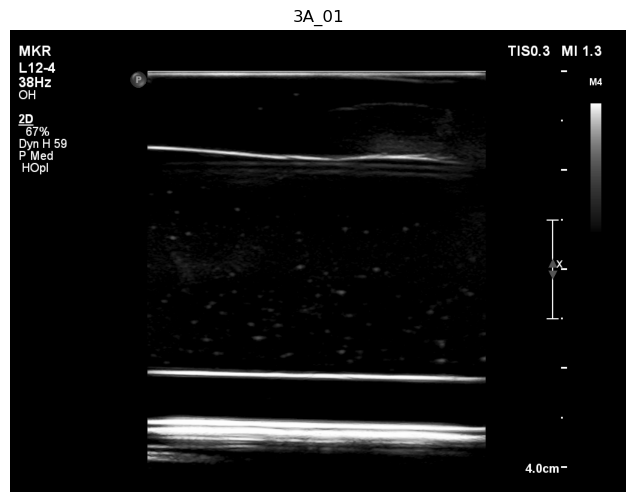

In [3]:
%matplotlib inline

name = "3A_01.dcm"                      # <- skift billede her
image, spacing = us_data[name]
aspect = spacing[0] / spacing[1] if spacing else 1

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(image, cmap="gray", aspect=aspect)
ax.set_title(name.replace(".dcm", ""))
ax.axis("off")
plt.show()

## Meta Data For Single Image

In [4]:
ds = pydicom.dcmread(US_DIR / "3A_01.dcm", stop_before_pixels=True)
print(ds.SequenceOfUltrasoundRegions[0])

(0018,6012) Region Spatial Format               US: 1
(0018,6014) Region Data Type                    US: 1
(0018,6016) Region Flags                        UL: 2
(0018,6018) Region Location Min X0              UL: 14
(0018,601A) Region Location Min Y0              UL: 38
(0018,601C) Region Location Max X1              UL: 1010
(0018,601E) Region Location Max Y1              UL: 758
(0018,6024) Physical Units X Direction          US: 3
(0018,6026) Physical Units Y Direction          US: 3
(0018,602C) Physical Delta X                    FD: 0.006077231763637607
(0018,602E) Physical Delta Y                    FD: 0.006077231763637607


## Cropping for Single Image

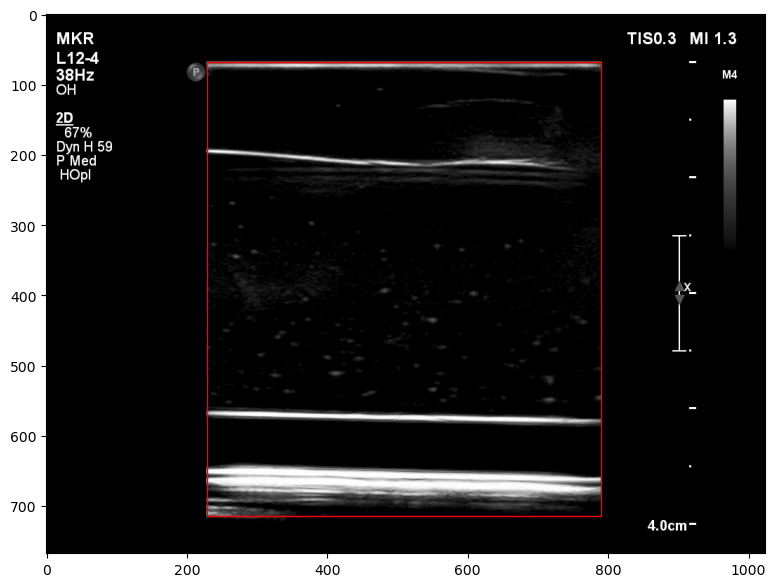

In [5]:
# Foreløbig boks (originalpixels), skal justeres
X0, X1 = 228, 790
Y0, Y1 = 68, 715

# Tjek på ét billede med aksemærker slået til
image, spacing = us_data["3A_01.dcm"]
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image, cmap="gray")
ax.add_patch(plt.Rectangle((X0, Y0), X1 - X0, Y1 - Y0, fill=False, ec="r", lw=1))
plt.show()

# All Six Images

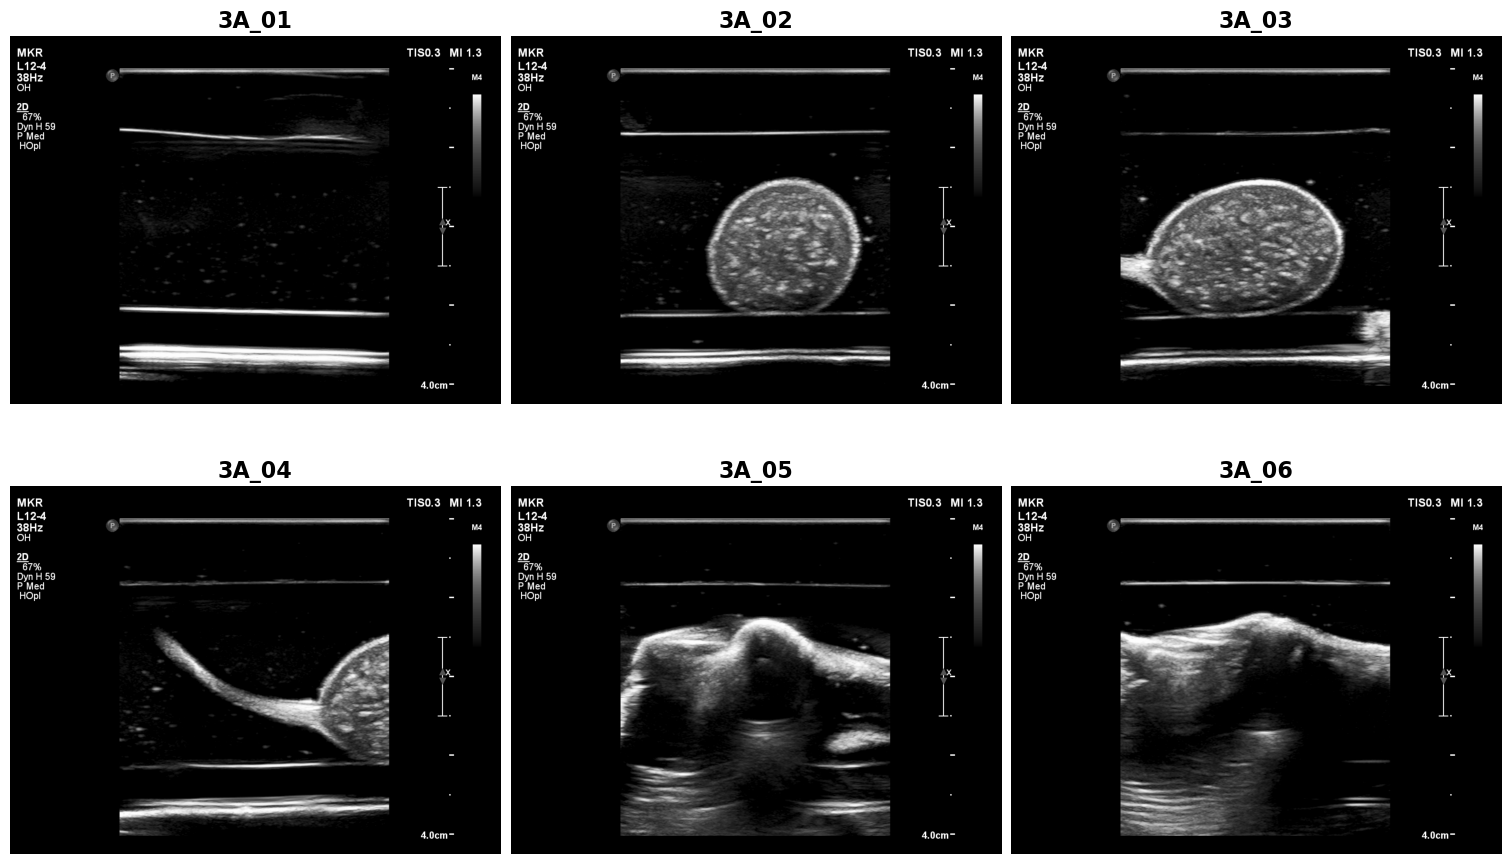

In [6]:
%matplotlib inline

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)

for ax, (name, (image, spacing)) in zip(axes.flat, us_data.items()):
    aspect = spacing[0] / spacing[1] if spacing else 1
    ax.imshow(image, cmap="gray", aspect=aspect)
    ax.set_title(name.replace(".dcm", ""), fontsize=16, fontweight="bold")
    ax.axis("off")

plt.show()

## Cropping of Six Images

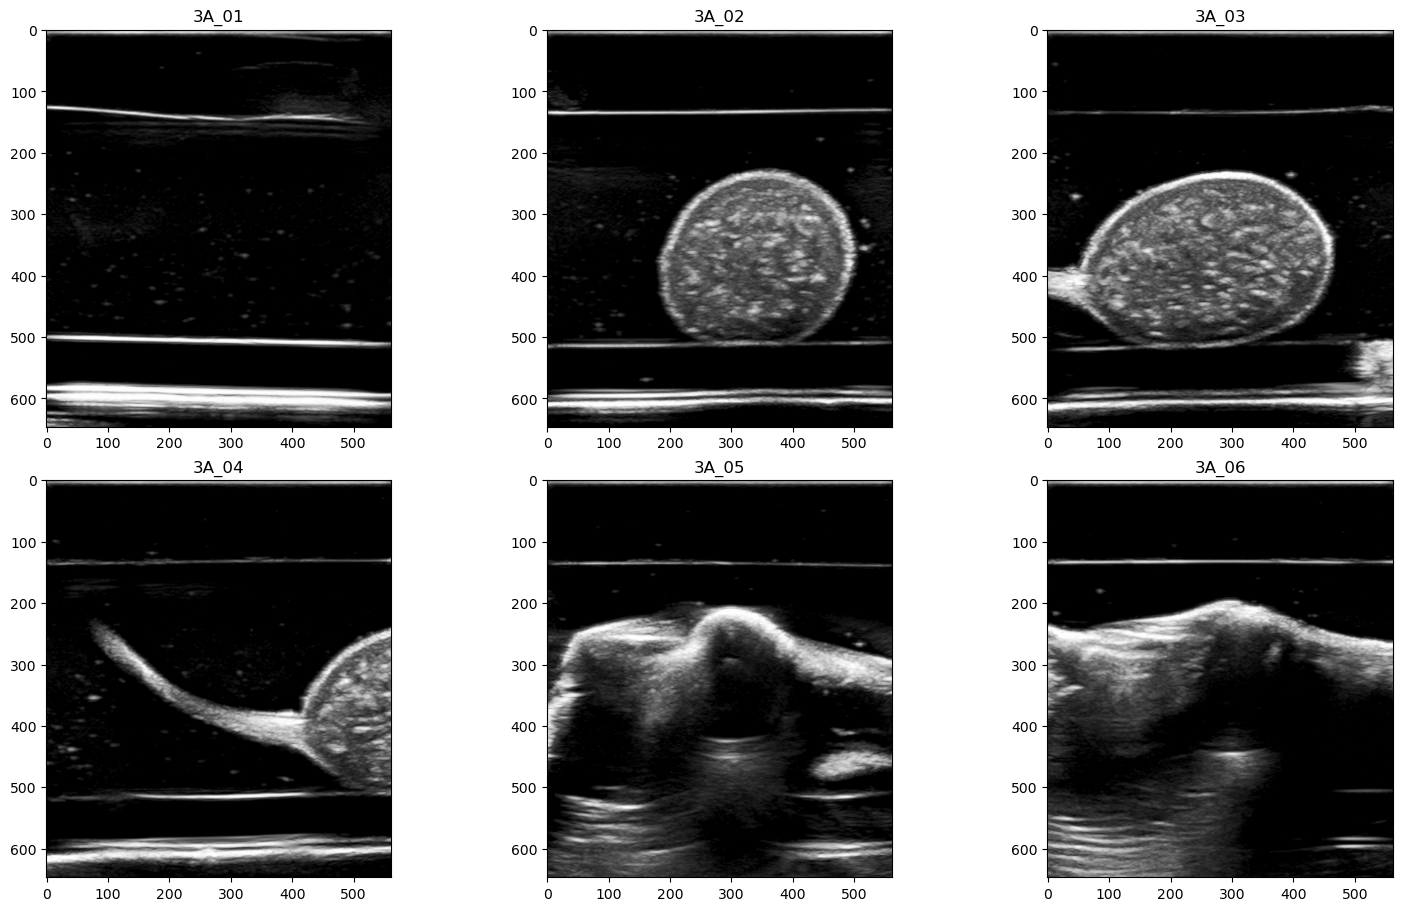

In [7]:

cropped = {name: img[Y0:Y1, X0:X1] for name, (img, _) in us_data.items()}

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for ax, (name, img) in zip(axes.flat, cropped.items()):
    ax.imshow(img, cmap="gray")
    ax.set_title(name.replace(".dcm", ""))
plt.show()

# Interactive measuring tool of Single Image

In [36]:
def distance_mm(p1, p2, spacing):
    dy, dx = spacing
    return np.hypot((p2[0] - p1[0]) * dx, (p2[1] - p1[1]) * dy)

def measure(image, spacing, title=""):
    aspect = spacing[0] / spacing[1]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(image, cmap="gray", aspect=aspect)
    ax.set_title(title or "Klik to punkter pr. måling")

    clicks, results = [], []

    def on_click(event):
        if event.inaxes != ax:
            return
        clicks.append((event.xdata, event.ydata))
        ax.plot(event.xdata, event.ydata, "r+")
        if len(clicks) % 2 == 0:
            p1, p2 = clicks[-2], clicks[-1]
            d = distance_mm(p1, p2, spacing)
            results.append(d)
            ax.plot(*zip(p1, p2), "r-", lw=2)
            ax.text(*p2, f"{d:.1f} mm", color="dodgerblue", fontsize=14, ha="left", va="bottom")
            print(f"Måling {len(results)}: {d:.2f} mm")
        fig.canvas.draw_idle()

    fig.canvas.mpl_connect("button_press_event", on_click)
    return results

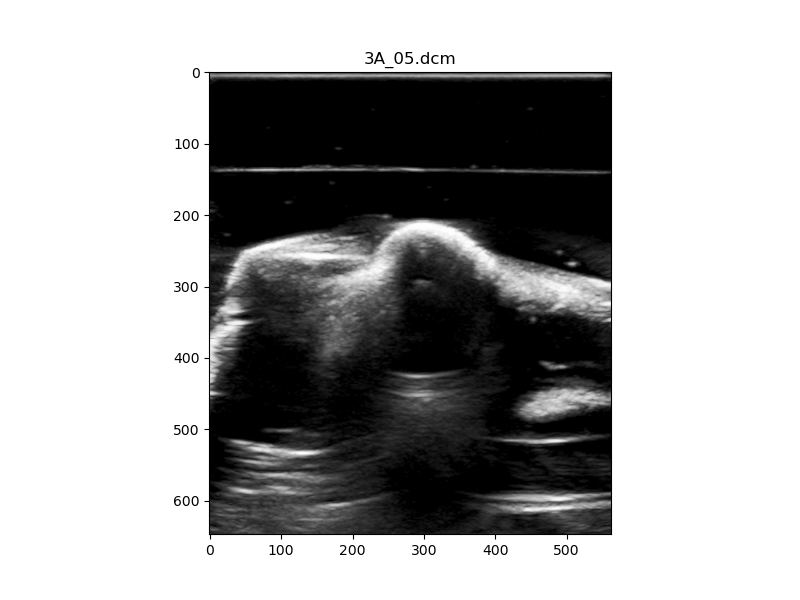

In [37]:
%matplotlib widget

name = "3A_05.dcm"                      # <- skift billede her
image = cropped[name]                   # beskåret billede
spacing = us_data[name][1]              # spacing er den samme efter beskæring
results = measure(image, spacing, title=name)

In [10]:
x = 8.4
y = 16
a = x/2
b = y/2
A1 = math.pi * a * b / 2
print(A1)

A2 = 11.9*2
print(A1+ A2+26.6)


52.778756580308524
103.17875658030852


In [11]:
pts = np.array([(256, 358), (415, 383), (412, 436), (258, 397)])   # hjørner i pixels, i rækkefølge
x, y = pts[:, 0], pts[:, 1]
area_px = 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

dy, dx = us_data["3A_03.dcm"][1]                  # mm/pixel (skift billede efter behov)
area_mm2 = area_px * dy * dx
print(f"Areal: {area_px:.0f} px² = {area_mm2:.1f} mm²")

Areal: 7215 px² = 26.6 mm²


# ROI

In [12]:
def roi_values(img, roi):
    """Return pixel intensities inside a rectangular ROI.

    roi = (x, y, width, height), all in pixels; x is column, y is row.
    The rectangle must lie completely inside the 2D image.
    """
    x, y, w, h = map(int, roi)
    if w <= 0 or h <= 0 or x < 0 or y < 0 or x+w > img.shape[1] or y+h > img.shape[0]:
        raise ValueError(f"ROI outside image: {roi}")
    # Array indexing is [row, column], the reverse of (x, y) notation.
    return np.asarray(img[y:y+h, x:x+w], float).ravel()

def roi_summary(img, roi):
    """Summarise an ROI with count, mean, median and within-ROI SD.

    Output intensity units are those of the input image. The standard
    deviation reflects ALL variation within the ROI (including structure,
    artefacts and noise); it is not automatically a noise estimate.
    """
    a = roi_values(img, roi)
    return {"n_pixels": len(a), "mean": float(a.mean()),
            "std_within_roi": float(a.std(ddof=1)) if len(a)>1 else np.nan,
            "median": float(np.median(a))}

## Image 3A_01

(647, 562)
    region  n_pixels størrelse_mm  mean  median   std  diff_vs_baggrund
Background      9600    7.3 x 4.9  1.04     0.0  4.45              0.00
  Ripples1      4800    4.9 x 3.6 44.00    33.0 46.82             42.96
  Ripples2      4800    4.9 x 3.6 25.56    12.0 36.62             24.52
  Ripples3      4800    4.9 x 3.6 24.86    20.0 23.58             23.81


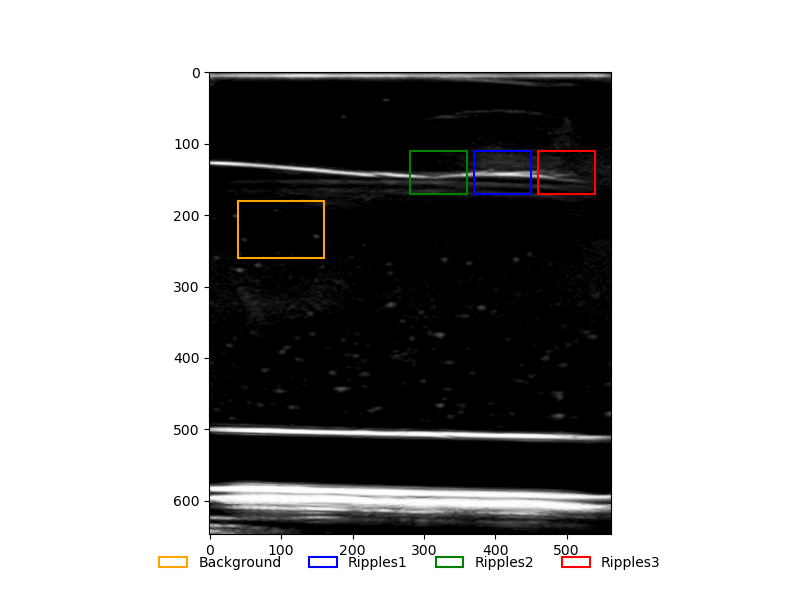

In [13]:

img = cropped["3A_01.dcm"]
dy, dx = spacing                          # mm/pixel (spacing for 3A_01)
print(img.shape)                          # (rows, columns) of the cropped image

# Name: (x, y, width, height) i pixels in the cropped image
rois = {
    "Background": (40, 180, 120, 80),
    "Ripples1":    (370, 110, 80, 60),
    "Ripples2":    (280, 110, 80, 60),
    "Ripples3":    (460, 110, 80, 60)
    
}

colors = {"Background": "orange", "Ripples1": "b", "Ripples2": "g", "Ripples3": "r"}

# --- Beregn ---
summ = {name: roi_summary(img, roi) for name, roi in rois.items()}
bg_mean = summ["Background"]["mean"]

rows = []
for name, s in summ.items():
    x, y, w, h = rois[name]
    rows.append({
        "region": name,
        "n_pixels": s["n_pixels"],
        "størrelse_mm": f"{w*dx:.1f} x {h*dy:.1f}",
        "mean": s["mean"],
        "median": s["median"],
        "std": s["std_within_roi"],
        "diff_vs_baggrund": s["mean"] - bg_mean,
    })

df = pd.DataFrame(rows)
print(df.round(2).to_string(index=False))

# --- Tegn ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img, cmap="gray")

for name, roi in rois.items():
    ax.add_patch(Rectangle(roi[:2], roi[2], roi[3], fill=False,
                           ec=colors[name], lw=1.5, label=name))

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02),
          ncol=len(rois), frameon=False)
plt.show()

## Image 3A_02

(647, 562)
    region  n_pixels størrelse_mm   mean  median   std  diff_vs_baggrund
Background      9600    7.3 x 4.9   1.66     0.0  5.65              0.00
    Inner1      9600    7.3 x 4.9  84.06    76.0 29.94             82.40
    Inner2      9600    7.3 x 4.9 108.21   100.0 32.38            106.54
    Inner3      9600    7.3 x 4.9 111.13   102.0 36.03            109.47
     Edge1       500    3.0 x 0.6 184.25   187.0 31.02            182.58
     Edge2       500    0.6 x 3.0 161.82   173.5 49.92            160.15
     Edge3       500    0.6 x 3.0 125.94   131.0 33.58            124.28


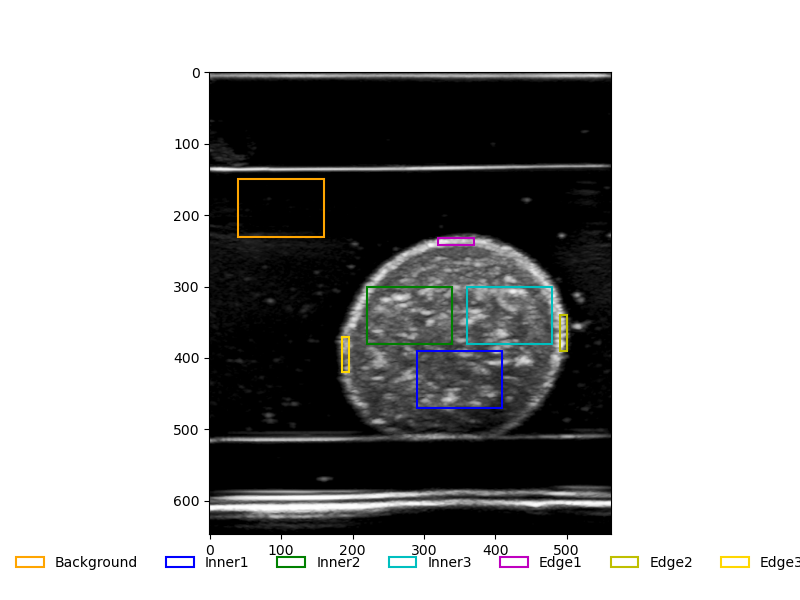

In [14]:

img = cropped["3A_02.dcm"]
dy, dx = spacing                          # mm/pixel (spacing for 3A_02)
print(img.shape)                          # (rows, columns) of the cropped image

# Name: (x, y, width, height) i pixels in the cropped image
rois = {
    "Background": (40, 150, 120, 80),
    "Inner1":    (290, 390, 120, 80),
    "Inner2":    (220, 300, 120, 80),
    "Inner3":    (360, 300, 120, 80),
    "Edge1":     (320, 232, 50, 10), 
    "Edge2":     (490, 340, 10, 50),
    "Edge3":     (185, 370, 10, 50)

         
}

colors = {"Background": "orange", "Inner1": "b", "Inner2": "g", "Inner3": "c", "Edge1": "m", "Edge2": "y", "Edge3": "gold"}

# --- Beregn ---
summ = {name: roi_summary(img, roi) for name, roi in rois.items()}
bg_mean = summ["Background"]["mean"]

rows = []
for name, s in summ.items():
    x, y, w, h = rois[name]
    rows.append({
        "region": name,
        "n_pixels": s["n_pixels"],
        "størrelse_mm": f"{w*dx:.1f} x {h*dy:.1f}",
        "mean": s["mean"],
        "median": s["median"],
        "std": s["std_within_roi"],
        "diff_vs_baggrund": s["mean"] - bg_mean,
    })

df = pd.DataFrame(rows)
print(df.round(2).to_string(index=False))

# --- Tegn ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img, cmap="gray")

for name, roi in rois.items():
    ax.add_patch(Rectangle(roi[:2], roi[2], roi[3], fill=False,
                           ec=colors[name], lw=1.5, label=name))

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02),
          ncol=len(rois), frameon=False)
plt.show()

## Image 3A_03

(647, 562)
    region  n_pixels størrelse_mm   mean  median   std  diff_vs_baggrund
Background      9600    7.3 x 4.9   0.01     0.0  0.21              0.00
    Inner1      9600    7.3 x 4.9 111.10   106.0 30.27            111.09
    Inner2      9600    7.3 x 4.9  86.82    82.0 26.45             86.81
    Inner3      9600    7.3 x 4.9 103.30    94.0 36.12            103.29
     Edge1       500    3.0 x 0.6 231.24   248.0 43.38            231.23
     Edge2       500    0.6 x 3.0 169.78   168.0 49.99            169.77
     Edge3       500    0.6 x 3.0 135.51   134.0 50.49            135.50
    Stalk1      1000    2.4 x 1.5 189.40   208.0 51.51            189.40
    Stalk2      1000    2.4 x 1.5 221.19   224.0 20.64            221.18
    Stalk3      1000    2.4 x 1.5 200.83   206.0 29.90            200.83


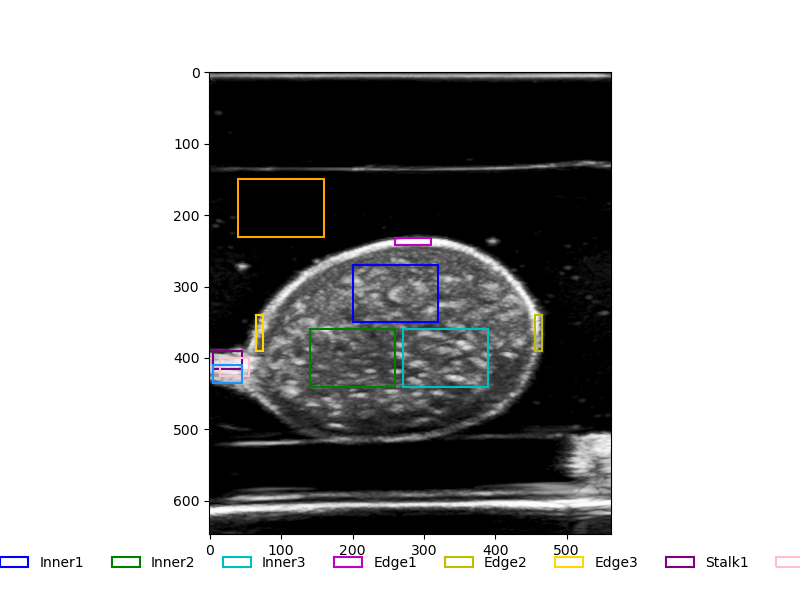

In [15]:

img = cropped["3A_03.dcm"]
dy, dx = spacing                          # mm/pixel (spacing for 3A_03)
print(img.shape)                          # (rows, columns) of the cropped image

# Name: (x, y, width, height) i pixels in the cropped image
rois = {
    "Background": (40, 150, 120, 80),
    "Inner1":    (200, 270, 120, 80),
    "Inner2":    (140, 360, 120, 80),
    "Inner3":    (270, 360, 120, 80),
    "Edge1":     (260, 232, 50, 10),
    "Edge2":     (455, 340, 10, 50),
    "Edge3":     (65, 340, 10, 50),
    "Stalk1":    (5, 390, 40, 25),
    "Stalk2":    (15, 400, 40, 25),
    "Stalk3":    (5, 410, 40, 25)
}

colors = {  "Background": "orange",
            "Inner1": "b", "Inner2": "g", "Inner3": "c",
            "Edge1": "m", "Edge2": "y","Edge3": "gold",
            "Stalk1": "purple", "Stalk2": "pink", "Stalk3": "dodgerblue"}

# --- Beregn ---
summ = {name: roi_summary(img, roi) for name, roi in rois.items()}
bg_mean = summ["Background"]["mean"]

rows = []
for name, s in summ.items():
    x, y, w, h = rois[name]
    rows.append({
        "region": name,
        "n_pixels": s["n_pixels"],
        "størrelse_mm": f"{w*dx:.1f} x {h*dy:.1f}",
        "mean": s["mean"],
        "median": s["median"],
        "std": s["std_within_roi"],
        "diff_vs_baggrund": s["mean"] - bg_mean,
    })

df = pd.DataFrame(rows)
print(df.round(2).to_string(index=False))

# --- Tegn ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img, cmap="gray")

for name, roi in rois.items():
    ax.add_patch(Rectangle(roi[:2], roi[2], roi[3], fill=False,
                           ec=colors[name], lw=1.5, label=name))

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02),
          ncol=len(rois), frameon=False)
plt.show()

## Image A3_04

(647, 562)
    region  n_pixels størrelse_mm   mean  median   std  diff_vs_baggrund
Background      9600    7.3 x 4.9   0.01     0.0  0.33              0.00
    Inner1      4800    4.9 x 3.6 124.66   119.0 38.18            124.64
    Inner2      4800    4.9 x 3.6 103.53    97.0 36.74            103.52
    Inner3      4800    4.9 x 3.6  69.40    62.0 30.08             69.39
     Edge1       500    3.0 x 0.6 145.49   156.0 56.46            145.47
     Edge2       500    0.6 x 3.0 127.62   130.5 48.49            127.61
     Edge3       500    0.6 x 3.0 107.06    98.0 35.29            107.05
    Stalk1      1000    2.4 x 1.5 196.72   200.0 22.94            196.70
    Stalk2      1000    2.4 x 1.5 200.64   197.0 26.64            200.63
    Stalk3      1000    2.4 x 1.5 134.78   140.0 26.88            134.76


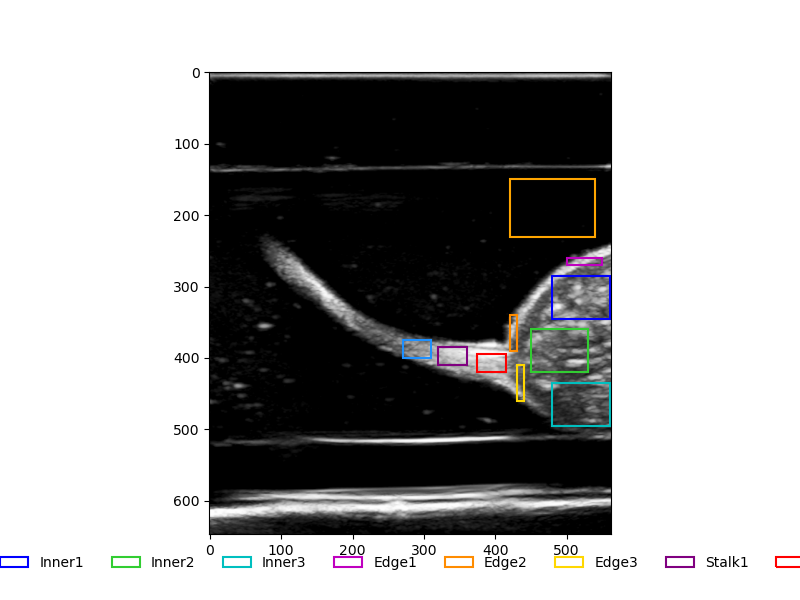

In [16]:

img = cropped["3A_04.dcm"]
dy, dx = spacing                          # mm/pixel (spacing for 3A_04)
print(img.shape)                          # (rows, columns) of the cropped image

# Name: (x, y, width, height) i pixels in the cropped image
rois = {
    "Background": (420, 150, 120, 80),
    "Inner1":    (480, 285, 80, 60),
    "Inner2":    (450, 360, 80, 60), 
    "Inner3":    (480, 435, 80, 60),
    "Edge1":     (500, 260, 50, 10),
    "Edge2":     (420, 340, 10, 50),
    "Edge3":     (430, 410, 10, 50),
    "Stalk1":    (320, 385, 40, 25),
    "Stalk2":    (375, 395, 40, 25),
    "Stalk3":    (270, 375, 40, 25)
}

colors = {"Background": "orange", "Inner1": "b", "Inner2": "limegreen", "Inner3": "c", 
          "Edge1": "m", "Edge2": "darkorange", "Edge3": "gold", 
          "Stalk1": "purple", "Stalk2": "red", "Stalk3": "dodgerblue"}

# --- Beregn ---
summ = {name: roi_summary(img, roi) for name, roi in rois.items()}
bg_mean = summ["Background"]["mean"]

rows = []
for name, s in summ.items():
    x, y, w, h = rois[name]
    rows.append({
        "region": name,
        "n_pixels": s["n_pixels"],
        "størrelse_mm": f"{w*dx:.1f} x {h*dy:.1f}",
        "mean": s["mean"],
        "median": s["median"],
        "std": s["std_within_roi"],
        "diff_vs_baggrund": s["mean"] - bg_mean,
    })

df = pd.DataFrame(rows)
print(df.round(2).to_string(index=False))

# --- Tegn ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img, cmap="gray")

for name, roi in rois.items():
    ax.add_patch(Rectangle(roi[:2], roi[2], roi[3], fill=False,
                           ec=colors[name], lw=1.5, label=name))

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02),
          ncol=len(rois), frameon=False)
plt.show()

## Image A3_05

(647, 562)
    region  n_pixels størrelse_mm   mean  median   std  diff_vs_baggrund
Background      9600    7.3 x 4.9   0.57     0.0  2.43              0.00
    Inner1      4800    4.9 x 3.6 147.91   165.0 59.01            147.34
    Inner2      4800    4.9 x 3.6 159.05   178.0 66.67            158.48
    Inner3      4800    4.9 x 3.6 158.54   161.0 51.43            157.98
  Ripples1     10400    7.9 x 4.9  79.98    73.0 34.05             79.41
  Ripples2     10400    7.9 x 4.9  51.64    45.0 27.60             51.07
  Ripples3     10400    7.9 x 4.9  62.51    37.0 63.61             61.95


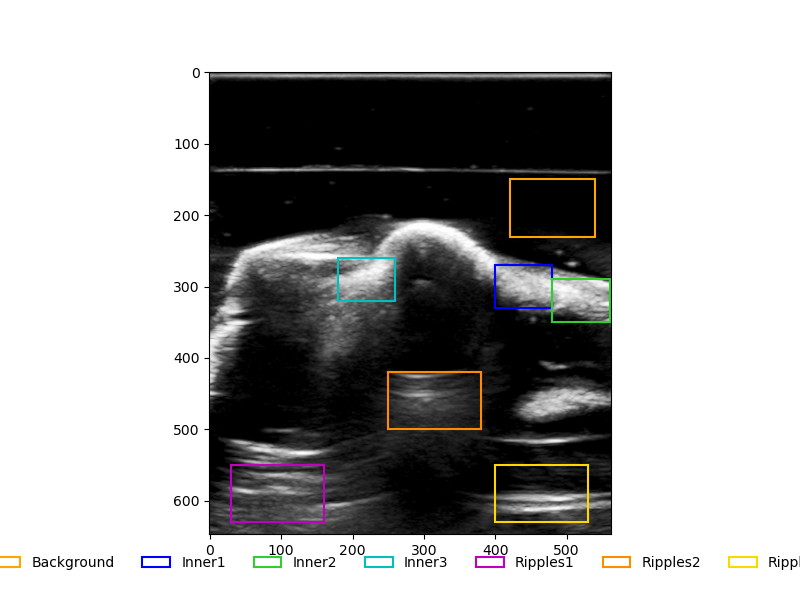

In [17]:

img = cropped["3A_05.dcm"]
dy, dx = spacing                          # mm/pixel (spacing for 3A_04)
print(img.shape)                          # (rows, columns) of the cropped image

# Name: (x, y, width, height) i pixels in the cropped image
rois = {
    "Background": (420, 150, 120, 80),
    "Inner1":    (400, 270, 80, 60),
    "Inner2":    (480, 290, 80, 60),
    "Inner3":    (180, 260, 80, 60),
    "Ripples1":     (30, 550, 130, 80),       
    "Ripples2":     (250, 420, 130, 80),
    "Ripples3":     (400, 550, 130, 80)
}

colors = {"Background": "orange", "Inner1": "b", "Inner2": "limegreen", "Inner3": "c", 
          "Ripples1": "m", "Ripples2": "darkorange", "Ripples3": "gold"}

# --- Beregn ---
summ = {name: roi_summary(img, roi) for name, roi in rois.items()}
bg_mean = summ["Background"]["mean"]

rows = []
for name, s in summ.items():
    x, y, w, h = rois[name]
    rows.append({
        "region": name,
        "n_pixels": s["n_pixels"],
        "størrelse_mm": f"{w*dx:.1f} x {h*dy:.1f}",
        "mean": s["mean"],
        "median": s["median"],
        "std": s["std_within_roi"],
        "diff_vs_baggrund": s["mean"] - bg_mean,
    })

df = pd.DataFrame(rows)
print(df.round(2).to_string(index=False))

# --- Tegn ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img, cmap="gray")

for name, roi in rois.items():
    ax.add_patch(Rectangle(roi[:2], roi[2], roi[3], fill=False,
                           ec=colors[name], lw=1.5, label=name))

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02),
          ncol=len(rois), frameon=False)
plt.show()

## Image A3_06

(647, 562)
    region  n_pixels størrelse_mm   mean  median   std  diff_vs_baggrund
Background      9600    7.3 x 4.9   0.58     0.0  3.82              0.00
     Edge1      4800    4.9 x 3.6 131.27   124.0 53.28            130.69
     Edge2      4800    4.9 x 3.6 134.81   119.0 60.28            134.23
     Edge3      4800    4.9 x 3.6 184.46   190.0 42.19            183.88
  Ripples1     10400    7.9 x 4.9 106.70   101.0 47.40            106.12
  Ripples2     10400    7.9 x 4.9  46.22    43.0 38.08             45.64
  Ripples3     10400    7.9 x 4.9  19.65     0.0 36.41             19.07


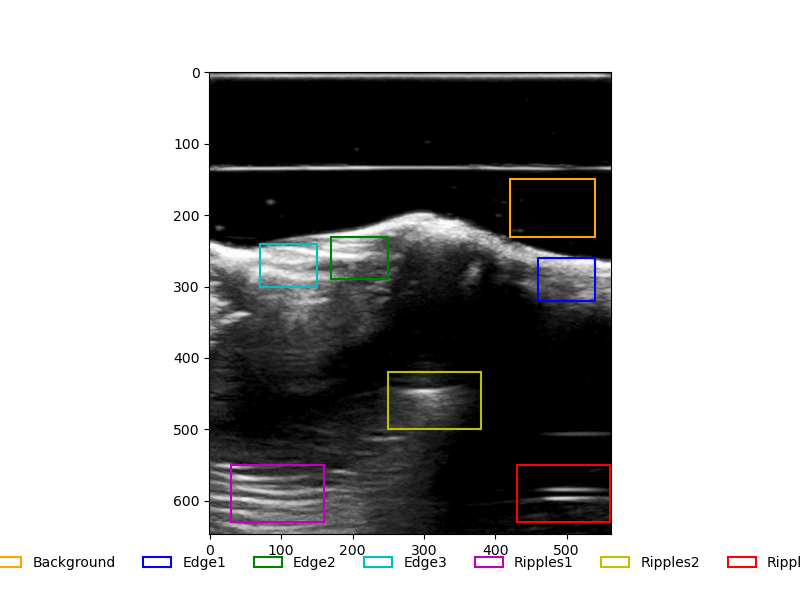

In [18]:

img = cropped["3A_06.dcm"]
dy, dx = spacing                          # mm/pixel (spacing for 3A_04)
print(img.shape)                          # (rows, columns) of the cropped image

# Name: (x, y, width, height) i pixels in the cropped image
rois = {
    "Background": (420, 150, 120, 80),
    "Edge1":    (460, 260, 80, 60),
    "Edge2":    (170, 230, 80, 60),
    "Edge3":    (70, 240, 80, 60),
    "Ripples1":     (30, 550, 130, 80),       
    "Ripples2":     (250, 420, 130, 80),
    "Ripples3":     (430, 550, 130, 80)
}

colors = {"Background": "orange", "Edge1": "b", "Edge2": "g", "Edge3": "c", "Ripples1": "m", "Ripples2": "y", "Ripples3": "r"}

# --- Beregn ---
summ = {name: roi_summary(img, roi) for name, roi in rois.items()}
bg_mean = summ["Background"]["mean"]

rows = []
for name, s in summ.items():
    x, y, w, h = rois[name]
    rows.append({
        "region": name,
        "n_pixels": s["n_pixels"],
        "størrelse_mm": f"{w*dx:.1f} x {h*dy:.1f}",
        "mean": s["mean"],
        "median": s["median"],
        "std": s["std_within_roi"],
        "diff_vs_baggrund": s["mean"] - bg_mean,
    })

df = pd.DataFrame(rows)
print(df.round(2).to_string(index=False))

# --- Tegn ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img, cmap="gray")

for name, roi in rois.items():
    ax.add_patch(Rectangle(roi[:2], roi[2], roi[3], fill=False,
                           ec=colors[name], lw=1.5, label=name))

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02),
          ncol=len(rois), frameon=False)
plt.show()

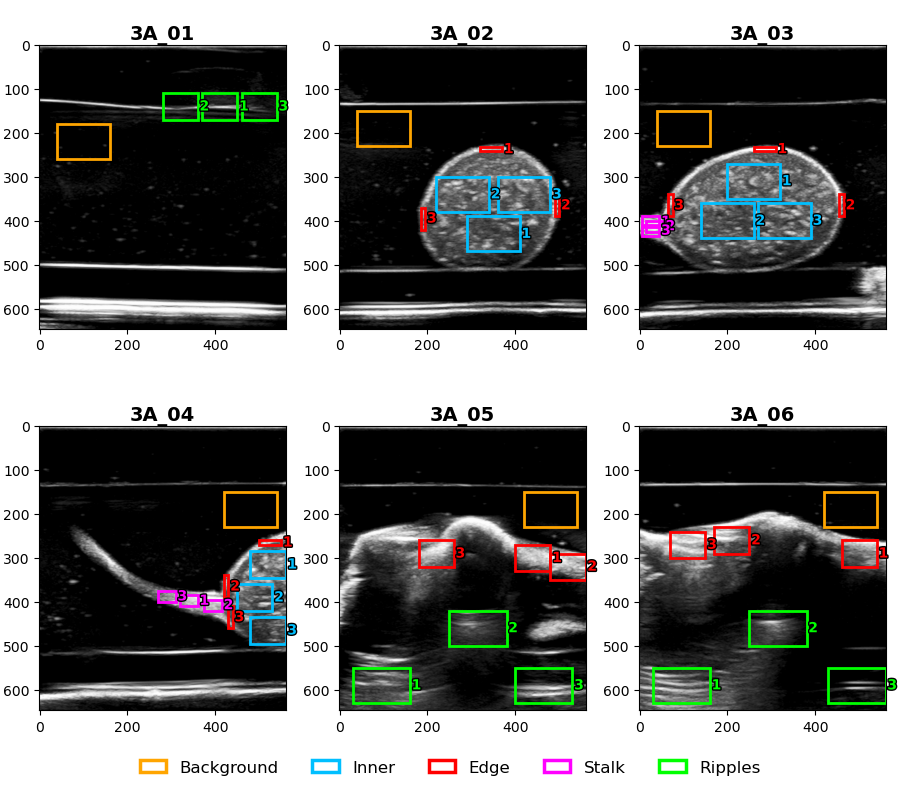

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.patheffects as pe

cropped = {name: img[Y0:Y1, X0:X1] for name, (img, _) in us_data.items()}

# ROI'er pr. billede: (x, y, bredde, højde) i pixels i det beskårne billede
all_rois = {
    "3A_01.dcm": {"Background": (40, 180, 120, 80),
                  "Ripples1": (370, 110, 80, 60), "Ripples2": (280, 110, 80, 60), "Ripples3": (460, 110, 80, 60)},
    "3A_02.dcm": {"Background": (40, 150, 120, 80),
                  "Inner1": (290, 390, 120, 80), "Inner2": (220, 300, 120, 80), "Inner3": (360, 300, 120, 80),
                  "Edge1": (320, 232, 50, 10), "Edge2": (490, 340, 10, 50), "Edge3": (185, 370, 10, 50)},
    "3A_03.dcm": {"Background": (40, 150, 120, 80),
                  "Inner1": (200, 270, 120, 80), "Inner2": (140, 360, 120, 80), "Inner3": (270, 360, 120, 80),
                  "Edge1": (260, 232, 50, 10), "Edge2": (455, 340, 10, 50), "Edge3": (65, 340, 10, 50),
                  "Stalk1": (5, 390, 40, 25), "Stalk2": (15, 400, 40, 25), "Stalk3": (5, 410, 40, 25)},
    "3A_04.dcm": {"Background": (420, 150, 120, 80),
                  "Inner1": (480, 285, 80, 60), "Inner2": (450, 360, 80, 60), "Inner3": (480, 435, 80, 60),
                  "Edge1": (500, 260, 50, 10), "Edge2": (420, 340, 10, 50), "Edge3": (430, 410, 10, 50),
                  "Stalk1": (320, 385, 40, 25), "Stalk2": (375, 395, 40, 25), "Stalk3": (270, 375, 40, 25)},
    "3A_05.dcm": {"Background": (420, 150, 120, 80),
                  "Edge1": (400, 270, 80, 60), "Edge2": (480, 290, 80, 60), "Edge3": (180, 260, 80, 60),
                  "Ripples1": (30, 550, 130, 80), "Ripples2": (250, 420, 130, 80), "Ripples3": (400, 550, 130, 80)},
    "3A_06.dcm": {"Background": (420, 150, 120, 80),
                  "Edge1": (460, 260, 80, 60), "Edge2": (170, 230, 80, 60), "Edge3": (70, 240, 80, 60),
                  "Ripples1": (30, 550, 130, 80), "Ripples2": (250, 420, 130, 80), "Ripples3": (430, 550, 130, 80)},
}

# Én farve pr. struktur (ens på tværs af billeder); nummeret står ved hver boks
colors = {"Background": "orange", "Inner": "deepskyblue", "Edge": "red",
          "Stalk": "magenta", "Ripples": "lime"}

h, w = next(iter(cropped.values())).shape[:2]
col_w = 3.0                                   # bredde pr. billede (inches)
fig, axes = plt.subplots(2, 3, figsize=(3 * col_w, 2 * col_w * h / w + 1.0),
                         layout="constrained")
fig.get_layout_engine().set(w_pad=0.03, h_pad=0.03, wspace=0.02, hspace=0.03)

for ax, (name, img) in zip(axes.flat, cropped.items()):
    ax.imshow(img, cmap="gray")
    for roi_name, (x, y, rw, rh) in all_rois[name].items():
        kind = roi_name.rstrip("0123456789")
        num = roi_name[len(kind):]
        ax.add_patch(Rectangle((x, y), rw, rh, fill=False, ec=colors[kind], lw=2))
        if num:                                # nummer ved boksen
            ax.text(x + rw + 4, y + rh / 2, num, color=colors[kind], fontsize=10,
                    fontweight="bold", va="center",
                    path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    ax.set_title(name.replace(".dcm", ""), fontsize=14, fontweight="bold", pad=4)
    ax.tick_params(labelsize=10)

# Fælles legend
handles = [Rectangle((0, 0), 1, 1, fill=False, ec=c, lw=2.5) for c in colors.values()]
fig.legend(handles, colors.keys(), loc="outside lower center",
           ncol=len(colors), frameon=False, fontsize=12, handlelength=1.6)
plt.show()

## CNR

In [20]:
def cnr(img, roi, bg_roi):
    a = roi_values(img, roi)
    b = roi_values(img, bg_roi)
    return abs(a.mean() - b.mean()) / np.sqrt(a.var(ddof=1) + b.var(ddof=1))

rows = []
for name, rois in all_rois.items():
    img = cropped[name]
    bg = rois["Background"]
    for roi_name, roi in rois.items():
        if roi_name == "Background":
            continue
        kind = roi_name.rstrip("0123456789")           # Inner, Edge, Stalk, Ripples
        rows.append({"image": name.replace(".dcm", ""), "structure": kind,
                     "roi": roi_name, "CNR": cnr(img, roi, bg)})

df_cnr = pd.DataFrame(rows)
print(df_cnr.round(2).to_string(index=False))

# Mean ± SD af CNR pr. struktur og billede
per_image = df_cnr.groupby(["structure", "image"])["CNR"].agg(["mean", "std"]).round(2)
print(per_image)

# Samlet pr. struktur (alle ROI'er)
pooled = df_cnr.groupby("structure")["CNR"].agg(["count", "mean", "std"]).round(2)
print(pooled)

image structure      roi   CNR
3A_01   Ripples Ripples1  0.91
3A_01   Ripples Ripples2  0.66
3A_01   Ripples Ripples3  0.99
3A_02     Inner   Inner1  2.70
3A_02     Inner   Inner2  3.24
3A_02     Inner   Inner3  3.00
3A_02      Edge    Edge1  5.79
3A_02      Edge    Edge2  3.19
3A_02      Edge    Edge3  3.65
3A_03     Inner   Inner1  3.67
3A_03     Inner   Inner2  3.28
3A_03     Inner   Inner3  2.86
3A_03      Edge    Edge1  5.33
3A_03      Edge    Edge2  3.40
3A_03      Edge    Edge3  2.68
3A_03     Stalk   Stalk1  3.68
3A_03     Stalk   Stalk2 10.72
3A_03     Stalk   Stalk3  6.72
3A_04     Inner   Inner1  3.26
3A_04     Inner   Inner2  2.82
3A_04     Inner   Inner3  2.31
3A_04      Edge    Edge1  2.58
3A_04      Edge    Edge2  2.63
3A_04      Edge    Edge3  3.03
3A_04     Stalk   Stalk1  8.58
3A_04     Stalk   Stalk2  7.53
3A_04     Stalk   Stalk3  5.01
3A_05      Edge    Edge1  2.49
3A_05      Edge    Edge2  2.38
3A_05      Edge    Edge3  3.07
3A_05   Ripples Ripples1  2.33
3A_05   

## SNR

In [21]:
def signaltonoise(a, axis=0, ddof=1):
    a = np.asanyarray(a)
    m = a.mean(axis)
    sd = a.std(axis=axis, ddof=ddof)
    return np.where(sd == 0, 0, m / sd)

rows = []
for name, rois in all_rois.items():
    img = cropped[name]
    for roi_name, roi in rois.items():
        if roi_name == "Background":              # springes over: mean ≈ 0, SNR meningsløs
            continue
        kind = roi_name.rstrip("0123456789")
        rows.append({"image": name.replace(".dcm", ""), "structure": kind,
                     "roi": roi_name, "SNR": float(signaltonoise(roi_values(img, roi)))})

df_snr = pd.DataFrame(rows)
print(df_snr.round(2).to_string(index=False))
print(df_snr.groupby("structure")["SNR"].agg(["count", "mean", "std"]).round(2))

image structure      roi   SNR
3A_01   Ripples Ripples1  0.94
3A_01   Ripples Ripples2  0.70
3A_01   Ripples Ripples3  1.05
3A_02     Inner   Inner1  2.81
3A_02     Inner   Inner2  3.34
3A_02     Inner   Inner3  3.08
3A_02      Edge    Edge1  5.94
3A_02      Edge    Edge2  3.24
3A_02      Edge    Edge3  3.75
3A_03     Inner   Inner1  3.67
3A_03     Inner   Inner2  3.28
3A_03     Inner   Inner3  2.86
3A_03      Edge    Edge1  5.33
3A_03      Edge    Edge2  3.40
3A_03      Edge    Edge3  2.68
3A_03     Stalk   Stalk1  3.68
3A_03     Stalk   Stalk2 10.72
3A_03     Stalk   Stalk3  6.72
3A_04     Inner   Inner1  3.26
3A_04     Inner   Inner2  2.82
3A_04     Inner   Inner3  2.31
3A_04      Edge    Edge1  2.58
3A_04      Edge    Edge2  2.63
3A_04      Edge    Edge3  3.03
3A_04     Stalk   Stalk1  8.58
3A_04     Stalk   Stalk2  7.53
3A_04     Stalk   Stalk3  5.01
3A_05      Edge    Edge1  2.51
3A_05      Edge    Edge2  2.39
3A_05      Edge    Edge3  3.08
3A_05   Ripples Ripples1  2.35
3A_05   

In [22]:
plt.close("all")
%matplotlib inline

In [23]:
# 1. Sampling: pixel size and field of view
dy, dx = us_data["3A_01.dcm"][1]; h, w = cropped["3A_01.dcm"].shape
print(f"Pixel size: {dy*1000:.1f} x {dx*1000:.1f} µm | cropped image: {w*dx:.1f} x {h*dy:.1f} mm (width x depth)")

# 2. Resolution from speckle size: width at half maximum of the ROI autocorrelation
def speckle_size(img, roi, dy, dx):
    x, y, w, h = roi
    a = img[y:y+h, x:x+w].astype(float); a -= a.mean()
    ac = np.fft.fftshift(np.fft.ifft2(np.abs(np.fft.fft2(a))**2).real); ac /= ac.max()
    return (ac[:, w//2] > .5).sum() * dy, (ac[h//2, :] > .5).sum() * dx     # axial, lateral [mm]

df_res = pd.DataFrame([(n[:-4], k, *speckle_size(cropped[n], r, *us_data[n][1]))
                       for n, rois in all_rois.items() for k, r in rois.items() if k.startswith("Inner")],
                      columns=["image", "roi", "axial_mm", "lateral_mm"])
print(df_res.round(2).to_string(index=False)); print(df_res[["axial_mm", "lateral_mm"]].agg(["mean", "std"]).round(2))

# 3. Resolution from a thin line: axial FWHM (adjust rows/columns to the line)
prof = cropped["3A_03.dcm"][115:150, 80:460].mean(axis=1)
print(f"Axial line width (FWHM): {(prof > prof.max()/2).sum() * dy:.2f} mm")

# 4. Image quality: background noise, black pixels and saturated pixels
for n, r in all_rois.items():
    x, y, w, h = r["Background"]; img = cropped[n]; bg = img[y:y+h, x:x+w]
    print(f"{n[:-4]}: bg mean {bg.mean():.2f}, bg std {bg.std(ddof=1):.2f}, zeros {100*(img==0).mean():.0f}%, saturated {100*(img>=250).mean():.1f}%")

# 5. Reverberation: echo depths relative to the first reflector (use columns without objects)
p = np.convolve(cropped["3A_03.dcm"][:, 480:560].mean(axis=1), np.ones(9)/9, "same"); z = np.arange(len(p)) * dy
pk = np.where((p[1:-1] > p[:-2]) & (p[1:-1] >= p[2:]) & (p[1:-1] > p.mean() + p.std()))[0] + 1
print("Echo depths [mm]:", z[pk].round(1), "| ratio to first reflector (8 mm):", (z[pk] / 8).round(1))   # ~2, 3, 4 suggests reverberation

# 6. Shadowing (negative) or enhancement (positive): ROI behind the object minus ROI beside it, same depth
shadow = lambda img, below, beside: roi_values(img, below).mean() - roi_values(img, beside).mean()
# print(shadow(cropped["3A_03.dcm"], (x, y, w, h), (x, y, w, h)))

Pixel size: 60.8 x 60.8 µm | cropped image: 34.2 x 39.3 mm (width x depth)
image    roi  axial_mm  lateral_mm
3A_02 Inner1      0.43        0.91
3A_02 Inner2      0.43        0.91
3A_02 Inner3      0.67        0.91
3A_03 Inner1      0.43        0.67
3A_03 Inner2      0.30        0.79
3A_03 Inner3      0.43        0.91
3A_04 Inner1      0.55        0.67
3A_04 Inner2      0.30        1.15
3A_04 Inner3      0.43        1.15
      axial_mm  lateral_mm
mean      0.44        0.90
std       0.11        0.18
Axial line width (FWHM): 0.30 mm
3A_01: bg mean 1.04, bg std 4.45, zeros 70%, saturated 1.8%
3A_02: bg mean 1.66, bg std 5.65, zeros 57%, saturated 0.5%
3A_03: bg mean 0.01, bg std 0.21, zeros 54%, saturated 0.5%
3A_04: bg mean 0.01, bg std 0.33, zeros 65%, saturated 0.4%
3A_05: bg mean 0.57, bg std 2.43, zeros 45%, saturated 0.4%
3A_06: bg mean 0.58, bg std 3.82, zeros 52%, saturated 0.4%
Echo depths [mm]: [ 0.2 31.1 32.2 33.  33.3 35.6 36.6] | ratio to first reflector (8 mm): [0.  3.9 4.

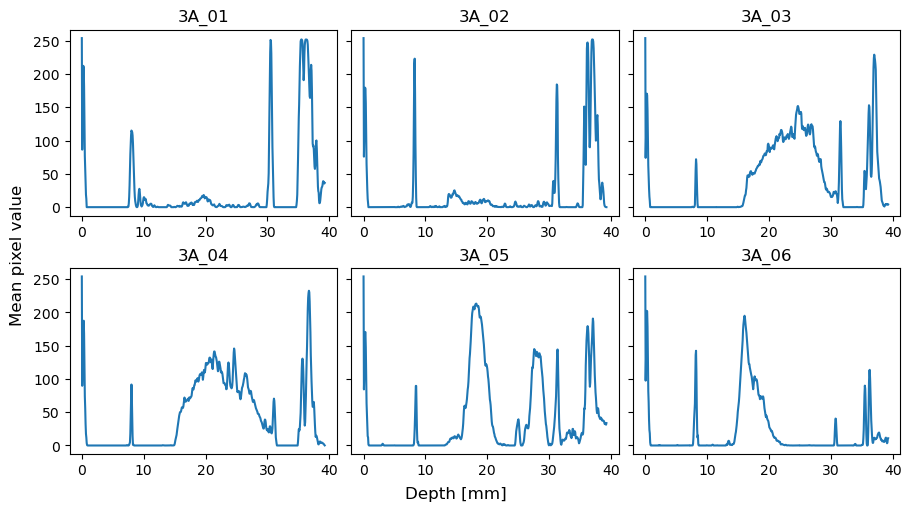

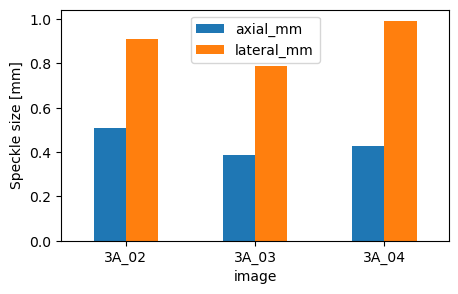

In [24]:
# 7. Plots for all images: depth profiles (columns of each image's Background ROI) and speckle size
fig, axes = plt.subplots(2, 3, figsize=(9, 5), sharey=True, layout="constrained")
for ax, (n, r) in zip(axes.flat, all_rois.items()):
    x, y, w, h = r["Background"]; p = cropped[n][:, x:x+w].mean(axis=1)
    ax.plot(np.arange(len(p)) * dy, p); ax.set_title(n[:-4])
fig.supxlabel("Depth [mm]"); fig.supylabel("Mean pixel value"); plt.show()

df_res.groupby("image")[["axial_mm", "lateral_mm"]].mean().plot.bar(figsize=(5, 3), ylabel="Speckle size [mm]", rot=0); plt.show()

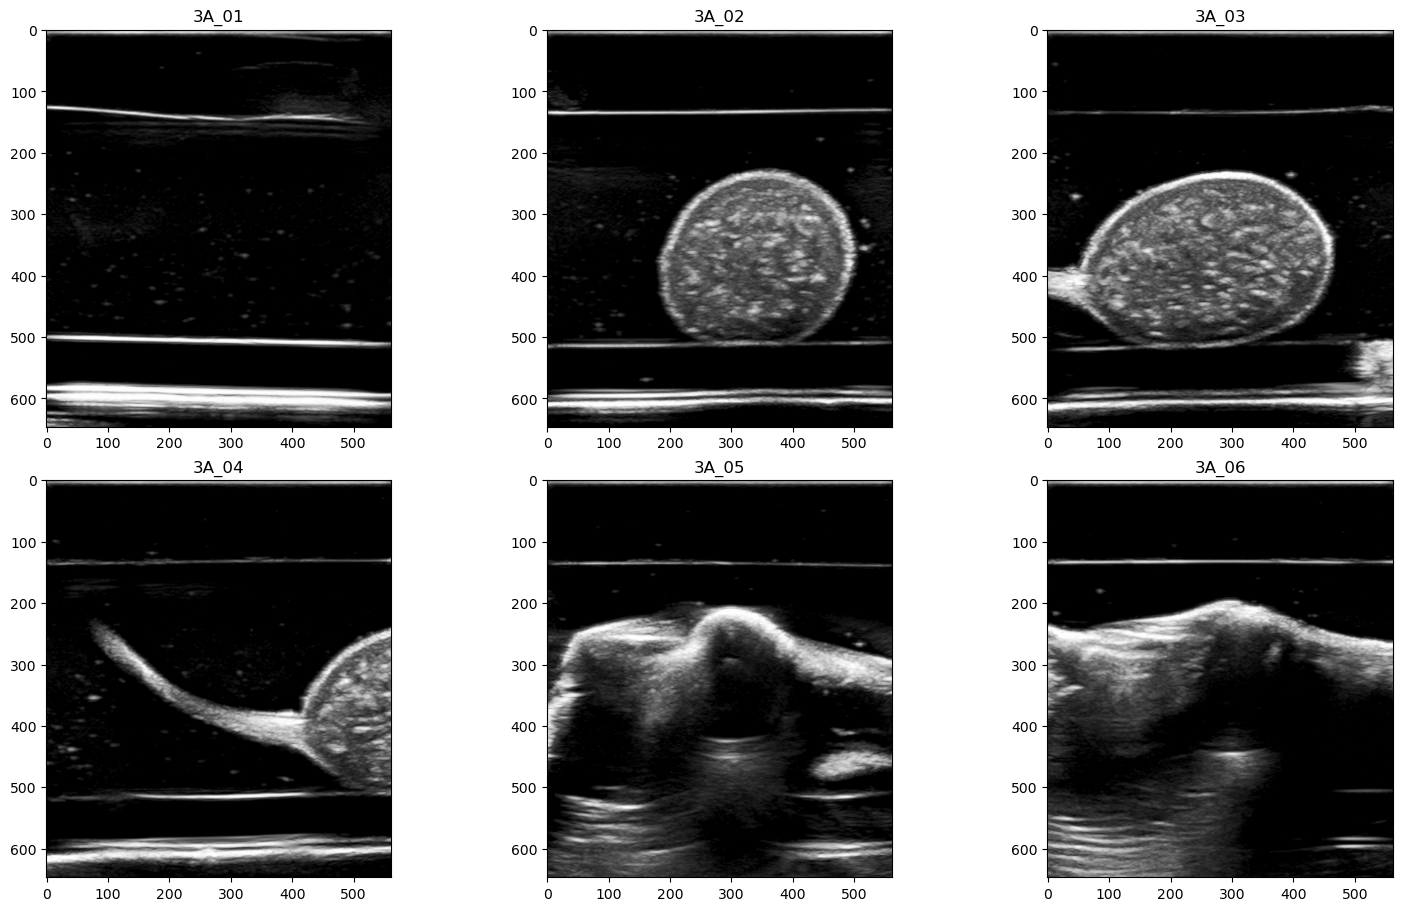

In [25]:

cropped = {name: img[Y0:Y1, X0:X1] for name, (img, _) in us_data.items()}

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for ax, (name, img) in zip(axes.flat, cropped.items()):
    ax.imshow(img, cmap="gray")
    ax.set_title(name.replace(".dcm", ""))
plt.show()

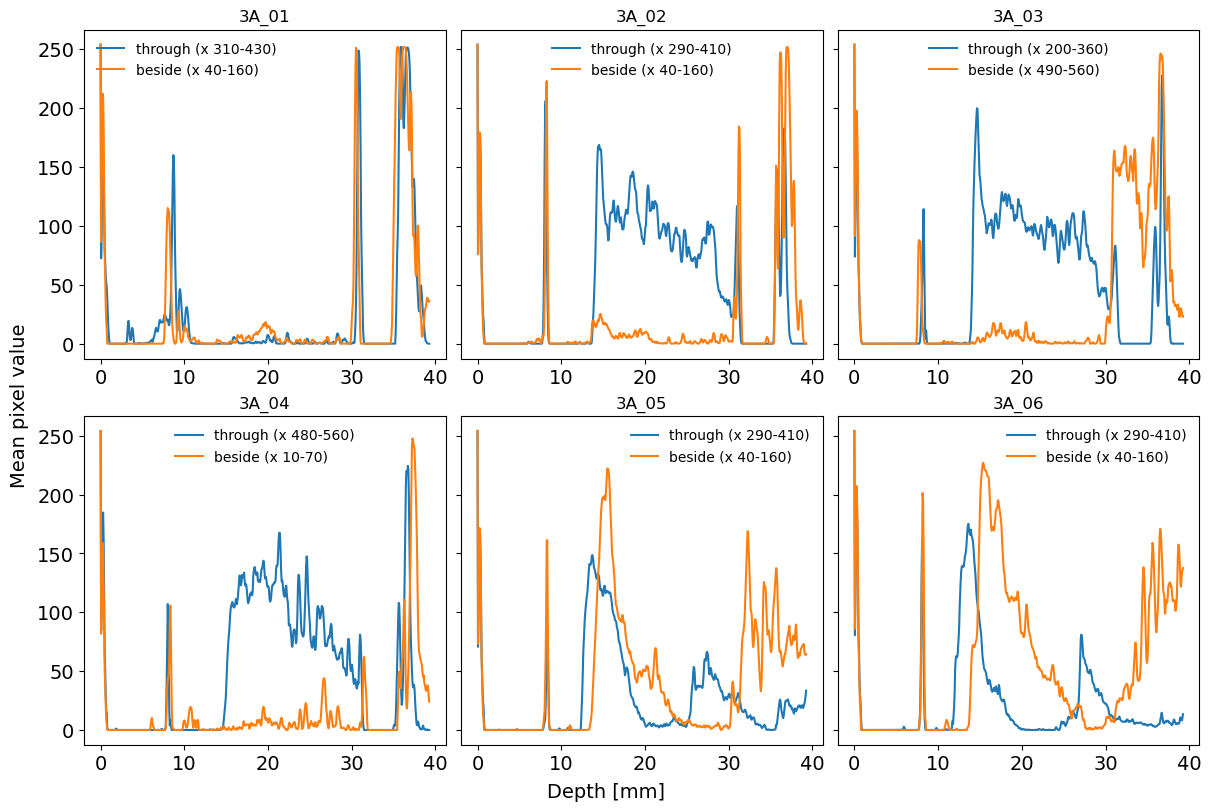

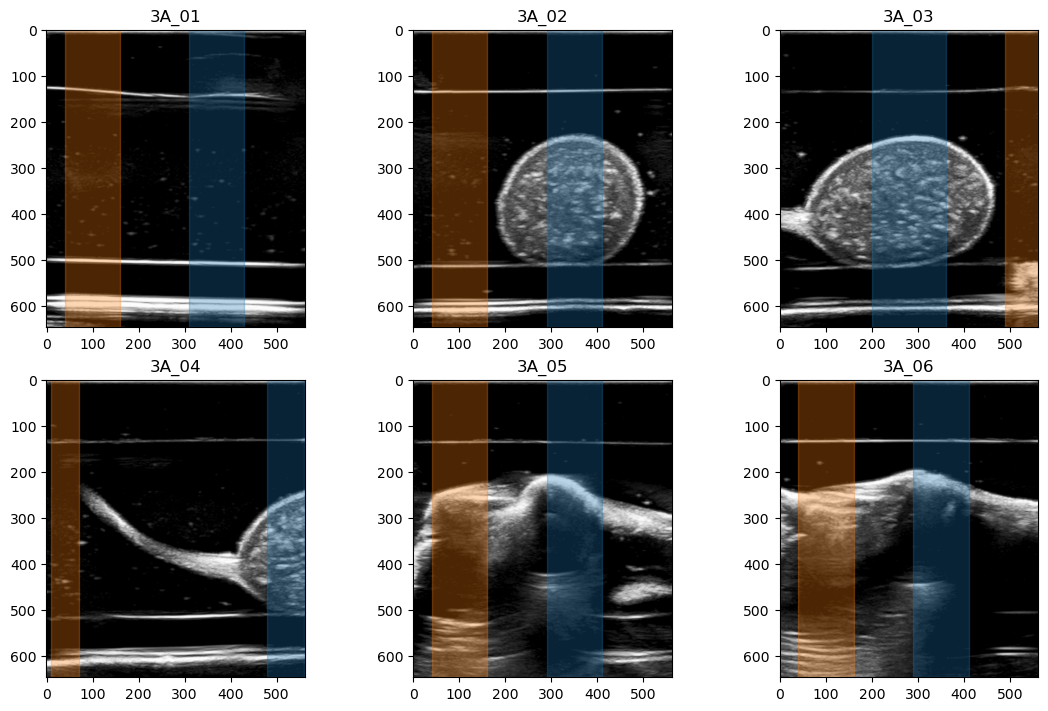

In [35]:
# Column ranges (x) per image: (first column, last column) in the CROPPED image. Adjust these per image.
strips = {
    "3A_01.dcm": {"through": (310, 430), "beside": (40, 160)},
    "3A_02.dcm": {"through": (290, 410), "beside": (40, 160)},
    "3A_03.dcm": {"through": (200, 360), "beside": (490, 560)},
    "3A_04.dcm": {"through": (480, 560), "beside": (10, 70)},
    "3A_05.dcm": {"through": (290, 410), "beside": (40, 160)},
    "3A_06.dcm": {"through": (290, 410), "beside": (40, 160)},
}

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True, layout="constrained")
for ax, (n, s) in zip(axes.flat, strips.items()):
    img = cropped[n]; z = np.arange(img.shape[0]) * us_data[n][1][0]       # depth [mm] = row * dy
    (t0, t1), (b0, b1) = s["through"], s["beside"]
    ax.plot(z, img[:, t0:t1].mean(axis=1), color="C0", label=f"through (x {t0}-{t1})")
    ax.plot(z, img[:, b0:b1].mean(axis=1), color="C1", label=f"beside (x {b0}-{b1})")
    ax.set_title(n[:-4]); ax.legend(frameon=False, fontsize=10)
    ax.tick_params(labelsize=14, labelbottom=True)                                           # axis numbers
fig.supxlabel("Depth [mm]", fontsize=14); fig.supylabel("Mean pixel value", fontsize=14); plt.show()

# Check: where do the strips lie in the images?
fig, axes = plt.subplots(2, 3, figsize=(11, 7), layout="constrained")
for ax, (n, s) in zip(axes.flat, strips.items()):
    ax.imshow(cropped[n], cmap="gray"); ax.set_title(n[:-4])
    for key, c in (("through", "C0"), ("beside", "C1")):
        ax.axvspan(*s[key], color=c, alpha=0.3)
plt.show()